# Week 1 · Exploratory Data Access & Schema Mapping

**Project:** Morrio Meridian customer retention analytics
**Question:** Why do customers cancel within the first 90 days despite positive onboarding scores, and which signals predict that early churn?

**Goal of this notebook**
1. Confirm each of the three exports loads and joins cleanly
2. Document every table's schema with annotations
3. Produce summary statistics for the columns that matter for retention
4. Record data quality issues *before* any churn number is calculated

Nothing here is cleaned in place. Issues are measured and flagged; handling decisions are proposed at the end and applied from Week 2.

Data: three exports taken **2026-10-22**, read from `../data/` (not committed to the repo).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

DATA = "../data/"
EXPORT_DATE = pd.Timestamp("2026-10-22")

accounts = pd.read_csv(DATA + "accounts.csv", parse_dates=["created_date"])
subs = pd.read_csv(DATA + "subscriptions.csv", parse_dates=["start_date", "end_date"])
events = pd.read_csv(DATA + "product_events.csv")
events["event_ts"] = pd.to_datetime(events["event_timestamp"], utc=True).dt.tz_localize(None)

for name, df in [("accounts", accounts), ("subscriptions", subs), ("product_events", events)]:
    print(f"{name:16s} {df.shape[0]:>7,} rows  {df.shape[1]:>2} columns")

accounts           1,014 rows  11 columns
subscriptions      1,055 rows   7 columns
product_events    56,999 rows   8 columns


## 1. Access and integrity checks
Primary keys, foreign keys and date ranges.

In [2]:
checks = pd.DataFrame([
    ("accounts.account_id unique",          accounts.account_id.is_unique),
    ("subscriptions.subscription_id unique", subs.subscription_id.is_unique),
    ("product_events.event_id unique",       events.event_id.is_unique),
    ("every subscription has an account",    subs.account_id.isin(accounts.account_id).all()),
    ("every event has an account",           events.account_id.isin(accounts.account_id).all()),
    ("every account has a subscription",     accounts.account_id.isin(subs.account_id).all()),
    ("every account has at least one event", accounts.account_id.isin(events.account_id).all()),
], columns=["check", "passes"])
checks

,check,passes
0,accounts.account_id unique,True
1,subscriptions.subscription_id unique,True
2,product_events.event_id unique,True
3,every subscription has an account,True
4,every event has an account,True
5,every account has a subscription,True
6,every account has at least one event,False


In [3]:
print("Accounts with no events at all:", (~accounts.account_id.isin(events.account_id)).sum())
print("Accounts created:     ", accounts.created_date.min().date(), "→", accounts.created_date.max().date())
print("Subscriptions started:", subs.start_date.min().date(), "→", subs.start_date.max().date())
print("Events:               ", events.event_ts.min(), "→", events.event_ts.max())

Accounts with no events at all: 21
Accounts created:      2025-04-30 → 2026-10-20
Subscriptions started: 2025-04-30 → 2026-10-20
Events:                2025-04-30 02:40:37 → 2026-10-21 23:44:22


## 2. Schema map

How the tables relate:

```
accounts (1 row per account_id)
   │ 1
   ├──< N  subscriptions   (account_id)   — billing lifecycle, Chargebee
   └──< N  product_events  (account_id)   — raw telemetry, append-only
```

Field-level map with types, missingness and my annotations:

In [4]:
notes = {
 # accounts
 ("accounts","account_id"): "PK. Test/internal accounts are mixed in (see §4).",
 ("accounts","account_name"): "Free text from CRM. Used to spot test accounts.",
 ("accounts","created_date"): "CRM record date; matches first subscription start.",
 ("accounts","customer_segment"): "5 values. intermodal is a thin segment.",
 ("accounts","contract_tier"): "CURRENT tier, not tier at signup. Inconsistent casing/spacing (§4).",
 ("accounts","onboarding_channel"): "4 values.",
 ("accounts","hq_region"): "5 values.",
 ("accounts","fleet_size"): "Vehicles at creation. Has missing values — genuinely missing, not 0.",
 ("accounts","annual_contract_value"): "USD per dictionary, but some values look like cents (§4).",
 ("accounts","onboarding_satisfaction_score"): "1–10 survey. Observed range is narrow and high (§3).",
 ("accounts","days_to_first_login"): "Derived field; does not agree with the event log (§4).",
 # subscriptions
 ("subscriptions","subscription_id"): "PK.",
 ("subscriptions","account_id"): "FK → accounts. Some accounts have 2 subscriptions.",
 ("subscriptions","plan"): "Includes 'pilot' — not a paid plan.",
 ("subscriptions","start_date"): "First day of subscription.",
 ("subscriptions","end_date"): "Empty = not ended as of export.",
 ("subscriptions","status"): "active / paused / cancelled as of export.",
 ("subscriptions","end_reason"): "Not every reason is a customer leaving (consolidation, pause).",
 # events
 ("product_events","event_id"): "PK assigned on ingest — unique even for duplicated events.",
 ("product_events","account_id"): "FK → accounts.",
 ("product_events","user_id"): "User within account (format <account>-U<n>).",
 ("product_events","event_type"): "9 types. route_optimization_run = core value action.",
 ("product_events","event_timestamp"): "UTC string. Some precede subscription start (§4).",
 ("product_events","platform"): "web / ios / android.",
 ("product_events","app_version"): "5 releases; check per release before trusting counts.",
}

rows = []
for tname, df in [("accounts", accounts), ("subscriptions", subs), ("product_events", events.drop(columns="event_ts"))]:
    for col in df.columns:
        s = df[col]
        rows.append({
            "table": tname, "column": col, "dtype": str(s.dtype),
            "non_null": int(s.notna().sum()), "missing": int(s.isna().sum()),
            "distinct": int(s.nunique()),
            "example": str(s.dropna().iloc[0]) if s.notna().any() else "",
            "annotation": notes.get((tname, col), ""),
        })
schema_map = pd.DataFrame(rows)
schema_map.to_csv("schema_map.csv", index=False)
schema_map

,table,column,dtype,non_null,missing,distinct,example,annotation
0,accounts,account_id,str,1014,0,1014,AC00001,PK. Test/internal accounts are mixed in (see §4).
1,accounts,account_name,str,1014,0,1007,Halcyon Freight Partners,Free text from CRM. Used to spot test accounts.
2,accounts,created_date,datetime64[us],1014,0,464,2025-08-22 00:00:00,CRM record date; matches first subscription st...
3,accounts,customer_segment,str,1014,0,5,freight_brokerage,5 values. intermodal is a thin segment.
4,accounts,contract_tier,str,1014,0,12,growth,"CURRENT tier, not tier at signup. Inconsistent..."
5,accounts,onboarding_channel,str,1014,0,4,self_serve,4 values.
6,accounts,hq_region,str,1014,0,5,northeast,5 values.
7,accounts,fleet_size,float64,919,95,471,266.0,Vehicles at creation. Has missing values — gen...
8,accounts,annual_contract_value,int64,1014,0,1001,122992,"USD per dictionary, but some values look like ..."
9,accounts,onboarding_satisfaction_score,float64,1014,0,265,8.79,1–10 survey. Observed range is narrow and high...


## 3. Summary statistics for retention-related columns

In [5]:
num_cols = ["fleet_size", "annual_contract_value", "onboarding_satisfaction_score", "days_to_first_login"]
num_summary = accounts[num_cols].describe(percentiles=[.25, .5, .75, .99]).T
num_summary["missing"] = accounts[num_cols].isna().sum()
num_summary.round(2)

,count,mean,std,min,25%,50%,75%,99%,max,missing
fleet_size,919.0,345.99,153.54,22.00,239.50,347.00,451.50,676.64,812.00,95
annual_contract_value,1014.0,183705.39,928827.66,9504.00,68638.00,98390.50,128209.00,229076.08,15790500.00,0
onboarding_satisfaction_score,1014.0,8.50,0.78,7.12,7.83,8.55,9.19,9.79,9.82,0
days_to_first_login,1014.0,18.36,8.29,1.00,12.00,18.00,24.00,37.00,45.00,0


In [6]:
for col in ["customer_segment", "onboarding_channel", "hq_region"]:
    print(accounts[col].value_counts().to_string(), "\n")

customer_segment
regional_trucking     261
last_mile_delivery    231
cold_chain            230
freight_brokerage     223
intermodal             69 

onboarding_channel
self_serve              526
customer_success_led    177
sales_assisted          160
partner_reseller        151 

hq_region
northeast    530
west         127
southeast    120
southwest    119
midwest      118 



In [7]:
print(subs.plan.value_counts().to_string(), "\n")
print(subs.status.value_counts().to_string(), "\n")
print(subs.end_reason.value_counts(dropna=False).to_string(), "\n")
print("Subscriptions per account:\n", subs.groupby("account_id").size().value_counts().to_string())

plan
growth          560
enterprise      171
professional    163
pilot           161 

status
active       671
cancelled    360
paused        24 

end_reason
NaN                         695
non_payment                  70
account_consolidated         60
downgrade_exit               60
customer_requested_pause     58
voluntary_cancellation       57
contract_not_renewed         55 

Subscriptions per account:
 1    973
2     41


In [8]:
ev_summary = (events.groupby("event_type")
              .agg(events=("event_id", "size"),
                   accounts=("account_id", "nunique"),
                   users=("user_id", "nunique"))
              .sort_values("events", ascending=False))
ev_summary["share_%"] = (100 * ev_summary.events / ev_summary.events.sum()).round(1)
ev_summary

,events,accounts,users,share_%
event_type,,,,
route_optimization_run,8635,639,2463,15.1
session_started,6311,897,2881,11.1
dashboard_viewed,6100,907,2887,10.7
team_member_invited,6030,915,2875,10.6
alert_rule_configured,6029,896,2915,10.6
vehicle_added,6007,893,2899,10.5
support_ticket_submitted,5984,902,2889,10.5
integration_connected,5957,900,2893,10.5
utilization_report_exported,5946,909,2855,10.4


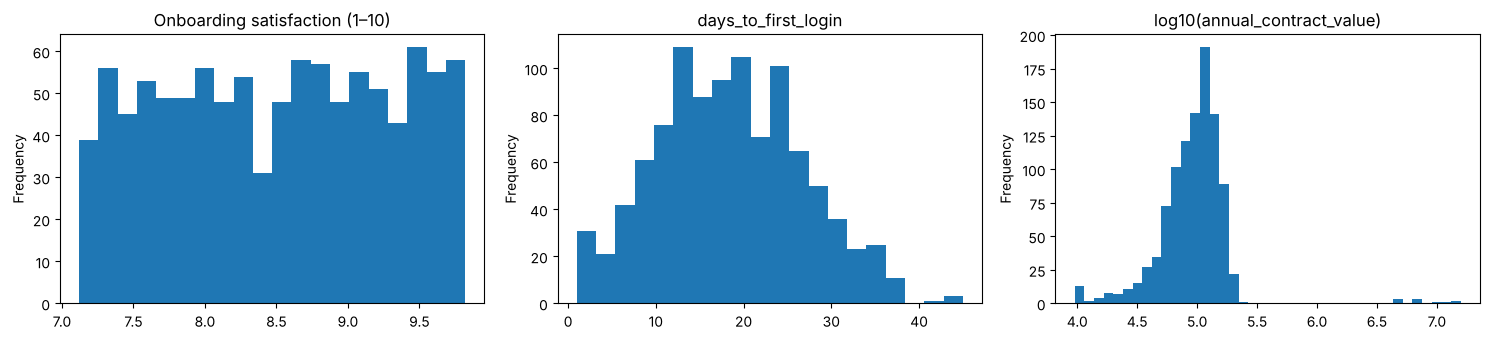

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
accounts.onboarding_satisfaction_score.plot.hist(bins=20, ax=axes[0], title="Onboarding satisfaction (1–10)")
accounts.days_to_first_login.plot.hist(bins=20, ax=axes[1], title="days_to_first_login")
np.log10(accounts.annual_contract_value).plot.hist(bins=40, ax=axes[2], title="log10(annual_contract_value)")
plt.tight_layout(); plt.show()

**Read-out:** satisfaction never goes below ~7 on a 1–10 scale — the score has almost no spread, so it cannot explain much on its own (and may only cover customers who finished onboarding). The ACV histogram has a separate cluster about two orders of magnitude above the rest.

## 4. Data quality issues found
Each check is measured here; nothing is removed yet.

### 4.1 Internal / test accounts in the CRM

In [10]:
test_pattern = r"test|demo|internal|qa\b|sandbox|do_not_bill|staging"
test_accts = accounts[accounts.account_name.str.contains(test_pattern, case=False, regex=True)]
print(len(test_accts), "test/internal accounts")
ev_per_acct = events.groupby("account_id").size()
print("Median events per account — test:", ev_per_acct.reindex(test_accts.account_id).median(),
      "| real:", ev_per_acct.drop(test_accts.account_id, errors="ignore").median())
test_accts[["account_id", "account_name", "contract_tier", "created_date"]]

14 test/internal accounts
Median events per account — test: 141.5 | real: 39.0


,account_id,account_name,contract_tier,created_date
1000,AC901001,Internal Demo,growth,2026-07-11
1001,AC901002,TEST Customer Success,growth,2026-07-20
1002,AC901003,QA Internal 2,growth,2026-08-17
1003,AC901004,Demo Account (Sales),professional,2026-08-22
1004,AC901005,Internal Demo,growth,2026-04-06
1005,AC901006,zz_test_staging,professional,2026-08-13
1006,AC901007,zz_test_staging,growth,2026-09-28
1007,AC901008,QA Internal 2,professional,2026-06-08
1008,AC901009,test_account_do_not_bill,enterprise,2026-05-16
1009,AC901010,test_account_do_not_bill,professional,2026-08-26


### 4.2 Inconsistent labels in `contract_tier`

In [11]:
print(accounts.contract_tier.map(repr).value_counts().to_string())
print("\nDistinct raw spellings:", accounts.contract_tier.nunique(),
      "→ after strip().lower():", accounts.contract_tier.str.strip().str.lower().nunique())

contract_tier
'growth'           476
'professional'     231
'enterprise'       228
'GROWTH'            15
'growth '           14
'Growth'            14
'Professional'       7
'PROFESSIONAL'       7
'ENTERPRISE'         7
'Enterprise'         6
'professional '      6
'enterprise '        3

Distinct raw spellings: 12 → after strip().lower(): 3


### 4.3 `annual_contract_value` — some values look like cents

In [12]:
acv = accounts.annual_contract_value
median = acv.median()
suspect = accounts[acv > 20 * median]
print(f"Median ACV ${median:,.0f}. {len(suspect)} accounts are >20× the median.")
print("Divided by 100 they fall in the normal range:")
print((suspect.annual_contract_value / 100).describe().round(0).to_string())
print(f"\nMean ACV as exported ${acv.mean():,.0f} vs with these /100: "
      f"${acv.where(acv <= 20*median, acv/100).mean():,.0f}")

Median ACV $98,390. 10 accounts are >20× the median.
Divided by 100 they fall in the normal range:
count        10.0
mean      86757.0
std       39974.0
min       49132.0
25%       53954.0
50%       70422.0
75%      107006.0
max      157905.0

Mean ACV as exported $183,705 vs with these /100: $99,002


### 4.4 Duplicate events

In [13]:
key = ["account_id", "user_id", "event_type", "event_timestamp", "platform", "app_version"]
dup_mask = events.duplicated(subset=key, keep="first")
print("Duplicate rows (identical except event_id):", dup_mask.sum())
events[dup_mask].groupby(["app_version", "platform", "event_type"]).size().rename("duplicates")

Duplicate rows (identical except event_id): 281


app_version  platform  event_type     
4.3.0        android   session_started    144
             ios       session_started    137
Name: duplicates, dtype: int64

In [14]:
# Sessions per active account-day by release, to see whether one version inflates counts
s = events[events.event_type == "session_started"].copy()
s["day"] = s.event_ts.dt.date
per_day = s.groupby(["app_version", "platform", "account_id", "day"]).size().groupby(["app_version", "platform"]).mean()
per_day.unstack().round(2)

platform,android,ios,web
app_version,,,
4.1.2,1.02,1.00,1.02
4.2.0,1.00,1.01,1.04
4.3.0,2.00,2.01,1.04
4.3.1,1.00,1.00,1.04
4.4.0,1.02,1.00,1.04


### 4.5 Events dated before the subscription started (backfilled history?)

In [15]:
first_start = subs.groupby("account_id").start_date.min()
ev = events.join(first_start, on="account_id")
early = ev[ev.event_ts < ev.start_date]
print("Events before the account's first subscription start:", len(early),
      "across", early.account_id.nunique(), "accounts")
print("Days before start:", (early.start_date - early.event_ts).dt.days.describe().round(1).to_string())

Events before the account's first subscription start: 36 across 32 accounts
Days before start: count    36.0
mean      6.8
std       4.5
min       0.0
25%       4.0
50%       6.0
75%       9.2
max      17.0


### 4.6 `days_to_first_login` vs the event log

In [16]:
first_session = events[events.event_type == "session_started"].groupby("account_id").event_ts.min()
cmp = accounts.set_index("account_id").join(first_session.rename("first_session"))
cmp["days_from_events"] = (cmp.first_session.dt.normalize() - cmp.created_date).dt.days
cmp["diff"] = cmp.days_from_events - cmp.days_to_first_login
print("Exact match:", (cmp["diff"] == 0).sum(), "of", cmp["diff"].notna().sum())
cmp["diff"].describe().round(1)

Exact match: 25 of 897


count    897.0
mean       0.9
std       29.7
min      -45.0
25%      -18.0
50%       -7.0
75%        9.0
max      184.0
Name: diff, dtype: float64

### 4.7 Subscriptions that are not simple churn signals

In [17]:
multi = subs.groupby("account_id").filter(lambda g: len(g) > 1).sort_values(["account_id", "start_date"])
print("Accounts with 2 subscriptions:", multi.account_id.nunique())
print("First-subscription plan for those accounts:\n",
      multi.groupby("account_id").first().plan.value_counts().to_string())
print("\nPaused subscriptions:", (subs.status == "paused").sum())
print("Pilot subscriptions:", (subs.plan == "pilot").sum())

Accounts with 2 subscriptions: 41
First-subscription plan for those accounts:
 plan
growth          26
professional     5
pilot            5
enterprise       5

Paused subscriptions: 24
Pilot subscriptions: 161


### 4.8 Right-censoring: accounts too new to judge 90-day churn

In [18]:
censored = first_start[first_start > EXPORT_DATE - pd.Timedelta(days=90)]
print(f"{len(censored)} accounts started within 90 days of the export ({(EXPORT_DATE - pd.Timedelta(days=90)).date()} or later).")
print("Their 90-day outcome is not yet observable — they cannot be labelled 'retained'.")

165 accounts started within 90 days of the export (2026-07-24 or later).
Their 90-day outcome is not yet observable — they cannot be labelled 'retained'.


## 5. Summary of issues and proposed handling

In [19]:
issues = pd.DataFrame([
 ("accounts", "Test / internal accounts", f"{len(test_accts)} accounts", "Exclude from all analysis"),
 ("accounts", "contract_tier casing/spacing", f"{accounts.contract_tier.nunique()} spellings of 3 values", "strip() + lower()"),
 ("accounts", "ACV entered in cents", f"{len(suspect)} values >20× median", "Divide by 100; confirm with Selin"),
 ("accounts", "fleet_size missing", f"{accounts.fleet_size.isna().sum()} accounts", "Keep as missing; don't impute 0"),
 ("accounts", "days_to_first_login disagrees with events", f"{(cmp['diff'].notna() & (cmp['diff'] != 0)).sum()} of {cmp['diff'].notna().sum()} disagree", "Recompute from event log"),
 ("accounts", "Satisfaction score compressed (7–10)", "no low scores", "Ask who receives the survey"),
 ("subscriptions", "Pilots, re-subscriptions, pauses", f"{(subs.plan=='pilot').sum()} pilots · {multi.account_id.nunique()} re-subs · {(subs.status=='paused').sum()} paused", "Decide churn definition in Week 2"),
 ("subscriptions", "Recent signups censored", f"{len(censored)} accounts", "Exclude from 90-day labels"),
 ("product_events", "Accounts with no events", f"{(~accounts.account_id.isin(events.account_id)).sum()} accounts", "Keep; treat as zero activity, not missing"),
 ("product_events", "Duplicate events", f"{dup_mask.sum()} rows", "Deduplicate on all fields except event_id; ask Priya"),
 ("product_events", "Events before subscription start", f"{len(early)} events", "Ask Priya about migration; exclude from first-30-day metrics"),
], columns=["table", "issue", "measured", "proposed handling"])
issues.to_csv("week1_issues.csv", index=False)
issues

,table,issue,measured,proposed handling
0,accounts,Test / internal accounts,14 accounts,Exclude from all analysis
1,accounts,contract_tier casing/spacing,12 spellings of 3 values,strip() + lower()
2,accounts,ACV entered in cents,10 values >20× median,Divide by 100; confirm with Selin
3,accounts,fleet_size missing,95 accounts,Keep as missing; don't impute 0
4,accounts,days_to_first_login disagrees with events,872 of 897 disagree,Recompute from event log
5,accounts,Satisfaction score compressed (7–10),no low scores,Ask who receives the survey
6,subscriptions,"Pilots, re-subscriptions, pauses",161 pilots · 41 re-subs · 24 paused,Decide churn definition in Week 2
7,subscriptions,Recent signups censored,165 accounts,Exclude from 90-day labels
8,product_events,Accounts with no events,21 accounts,"Keep; treat as zero activity, not missing"
9,product_events,Duplicate events,281 rows,Deduplicate on all fields except event_id; ask...


## 6. Open questions
1. **Churn definition** — does a pilot that ends without converting count? Do consolidation and pause count? *(Selin, Week 2)*
2. **Duplicate sessions** — is the duplication a known client bug in one release? Are other event types affected? *(Priya)*
3. **Pre-start events** — were these migrated from the old system, and should they be dropped? *(Priya)*
4. **ACV units** — are the large values cents, or real large contracts? *(Selin / finance)*
5. **Satisfaction survey** — who receives it, and what happens to customers who don't respond? *(Marcus)*
6. **`contract_tier`** is the *current* tier — can we get the tier at signup from subscriptions instead?